# 07_02 – EGCC: временной провал и доступность C40

Отдельный разбор всех исходных и сохраненных записей аэропорта. Цель – отделить отсутствие данных от отсутствия полетов и объяснить влияние прежнего отбора. Новые исключения не применяются. Пересчет: `.\.venv\Scripts\python.exe -u -X utf8 europe/scripts/audit_egcc.py` из корня проекта.

In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'europe/scripts/audit_egcc.py').exists())
REPORT=ROOT/'europe/reports/airports/EGCC'
FIGURES=ROOT/'europe/figures/07_airports/EGCC'
audit=json.loads((REPORT/'07_02_audit.json').read_text(encoding='utf8'))
with (ROOT/'europe/data/analytical/06_05_cases_excluded.parquet').open('rb') as stream:
    assert hashlib.file_digest(stream,'sha256').hexdigest()==audit['input_sha256']
reasons=pd.read_csv(REPORT/'07_02_period_reasons.csv')
assert int(reasons.rows.sum())==audit['source_rows']
assert int(reasons.go_arounds.sum())==audit['source_go_arounds']
display(pd.Series(audit))
display(reasons)


checked_date                                                               2026-10-09
airport                                                                          EGCC
input_sha256                        1111c7480ff7615042a332c586c8f60459bf5d6000da11...
source_sha256                       1160bdbea6fa93249a00768452be64047c6d2461bb0843...
source_rows                                                                    211299
source_go_arounds                                                                 791
current_rows                                                                    87435
current_go_arounds                                                                306
cutoff_utc                                                  2021-03-01T00:00:00+00:00
source_after_cut_rows                                                          106096
source_after_cut_go_arounds                                                       401
all_c40_missing_after_cut                             

,period,selection_reason,rows,go_arounds,goa_false,ga_percent,wilson_lower_percent,wilson_upper_percent,max_deviation_pp
0,before_2021_03,ambiguous_pair_04_08,6,0,6,0.000000,0.000000,39.033429,39.033429
1,before_2021_03,missing,17762,84,17678,0.472920,0.382179,0.585079,0.112159
2,before_2021_03,retained,87435,306,87129,0.349974,0.312952,0.391359,0.041385
3,from_2021_03,missing,106096,401,105695,0.377960,0.342790,0.416722,0.038763


## Покрытие и две метки

Верхняя панель: число записей. Нижняя: сохраненная доля каждой исходной метки. Пунктир отмечает март 2021.

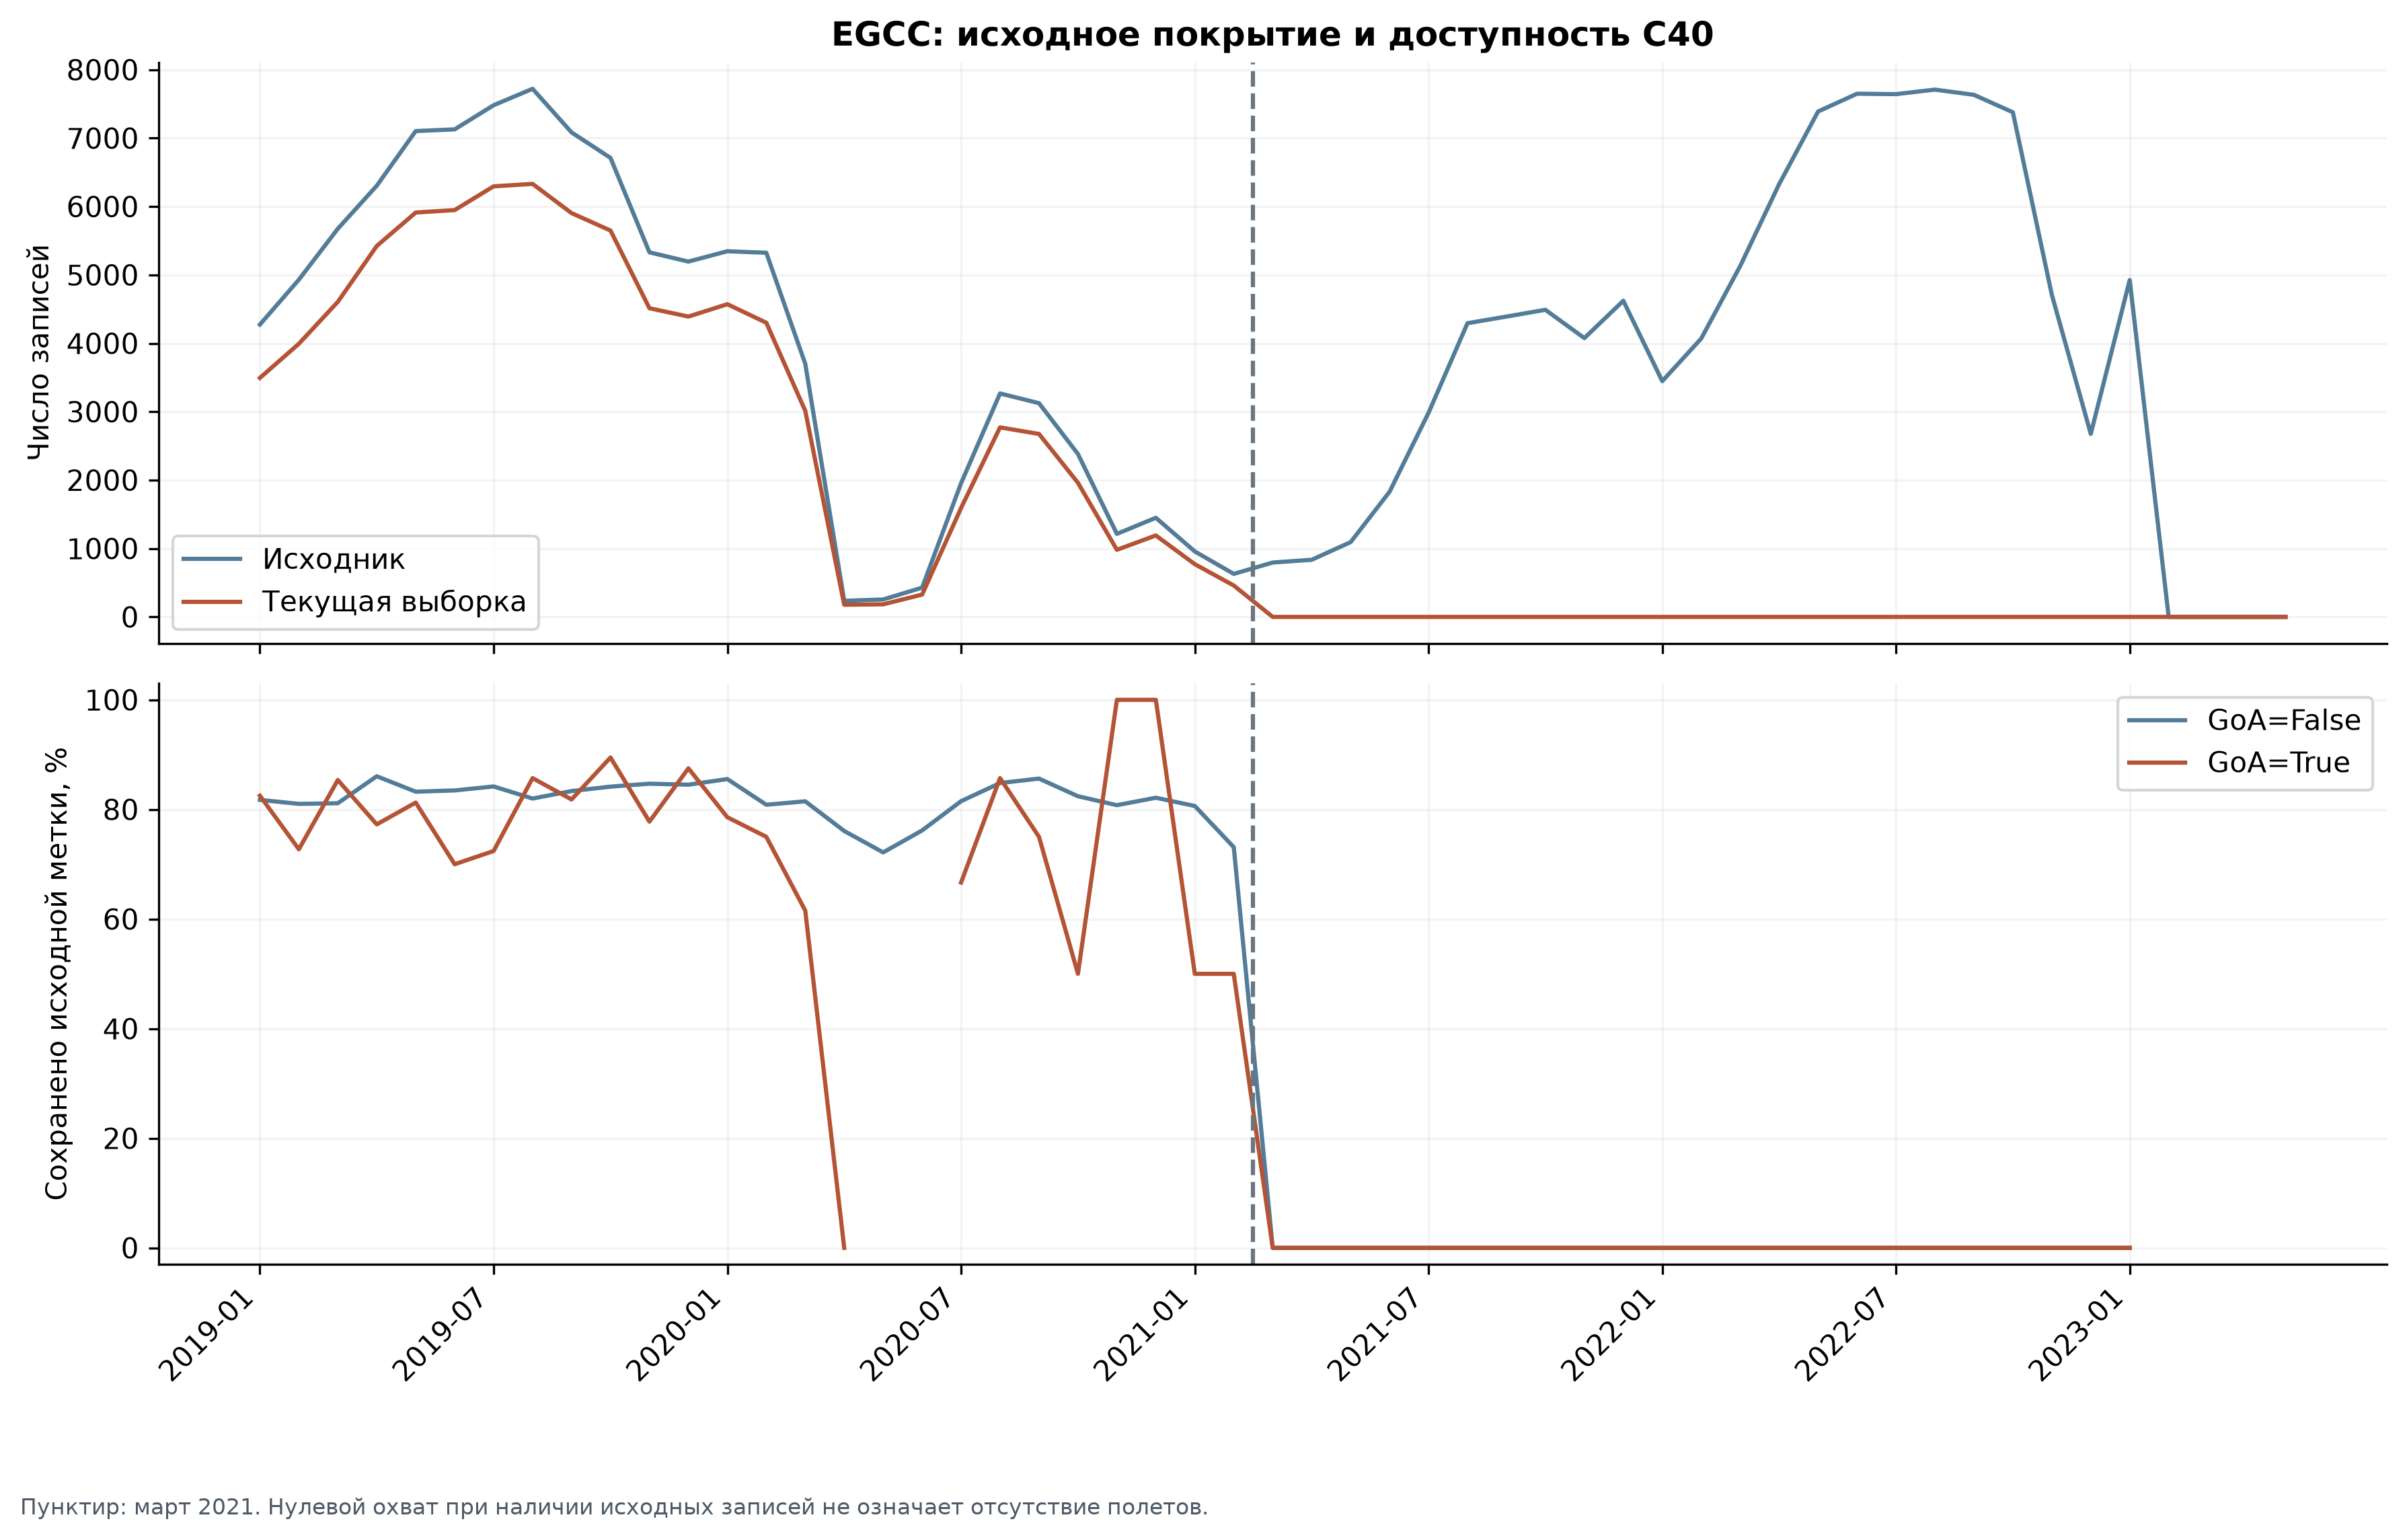

In [2]:
display(Image(filename=str(FIGURES/'07_02_egcc_coverage.png')))

## Доли GoA по одинаковым месяцам

Отсутствие текущей группы отображается разрывом, а не нулевой долей. Интервалы точечные, независимость наблюдений не доказана.

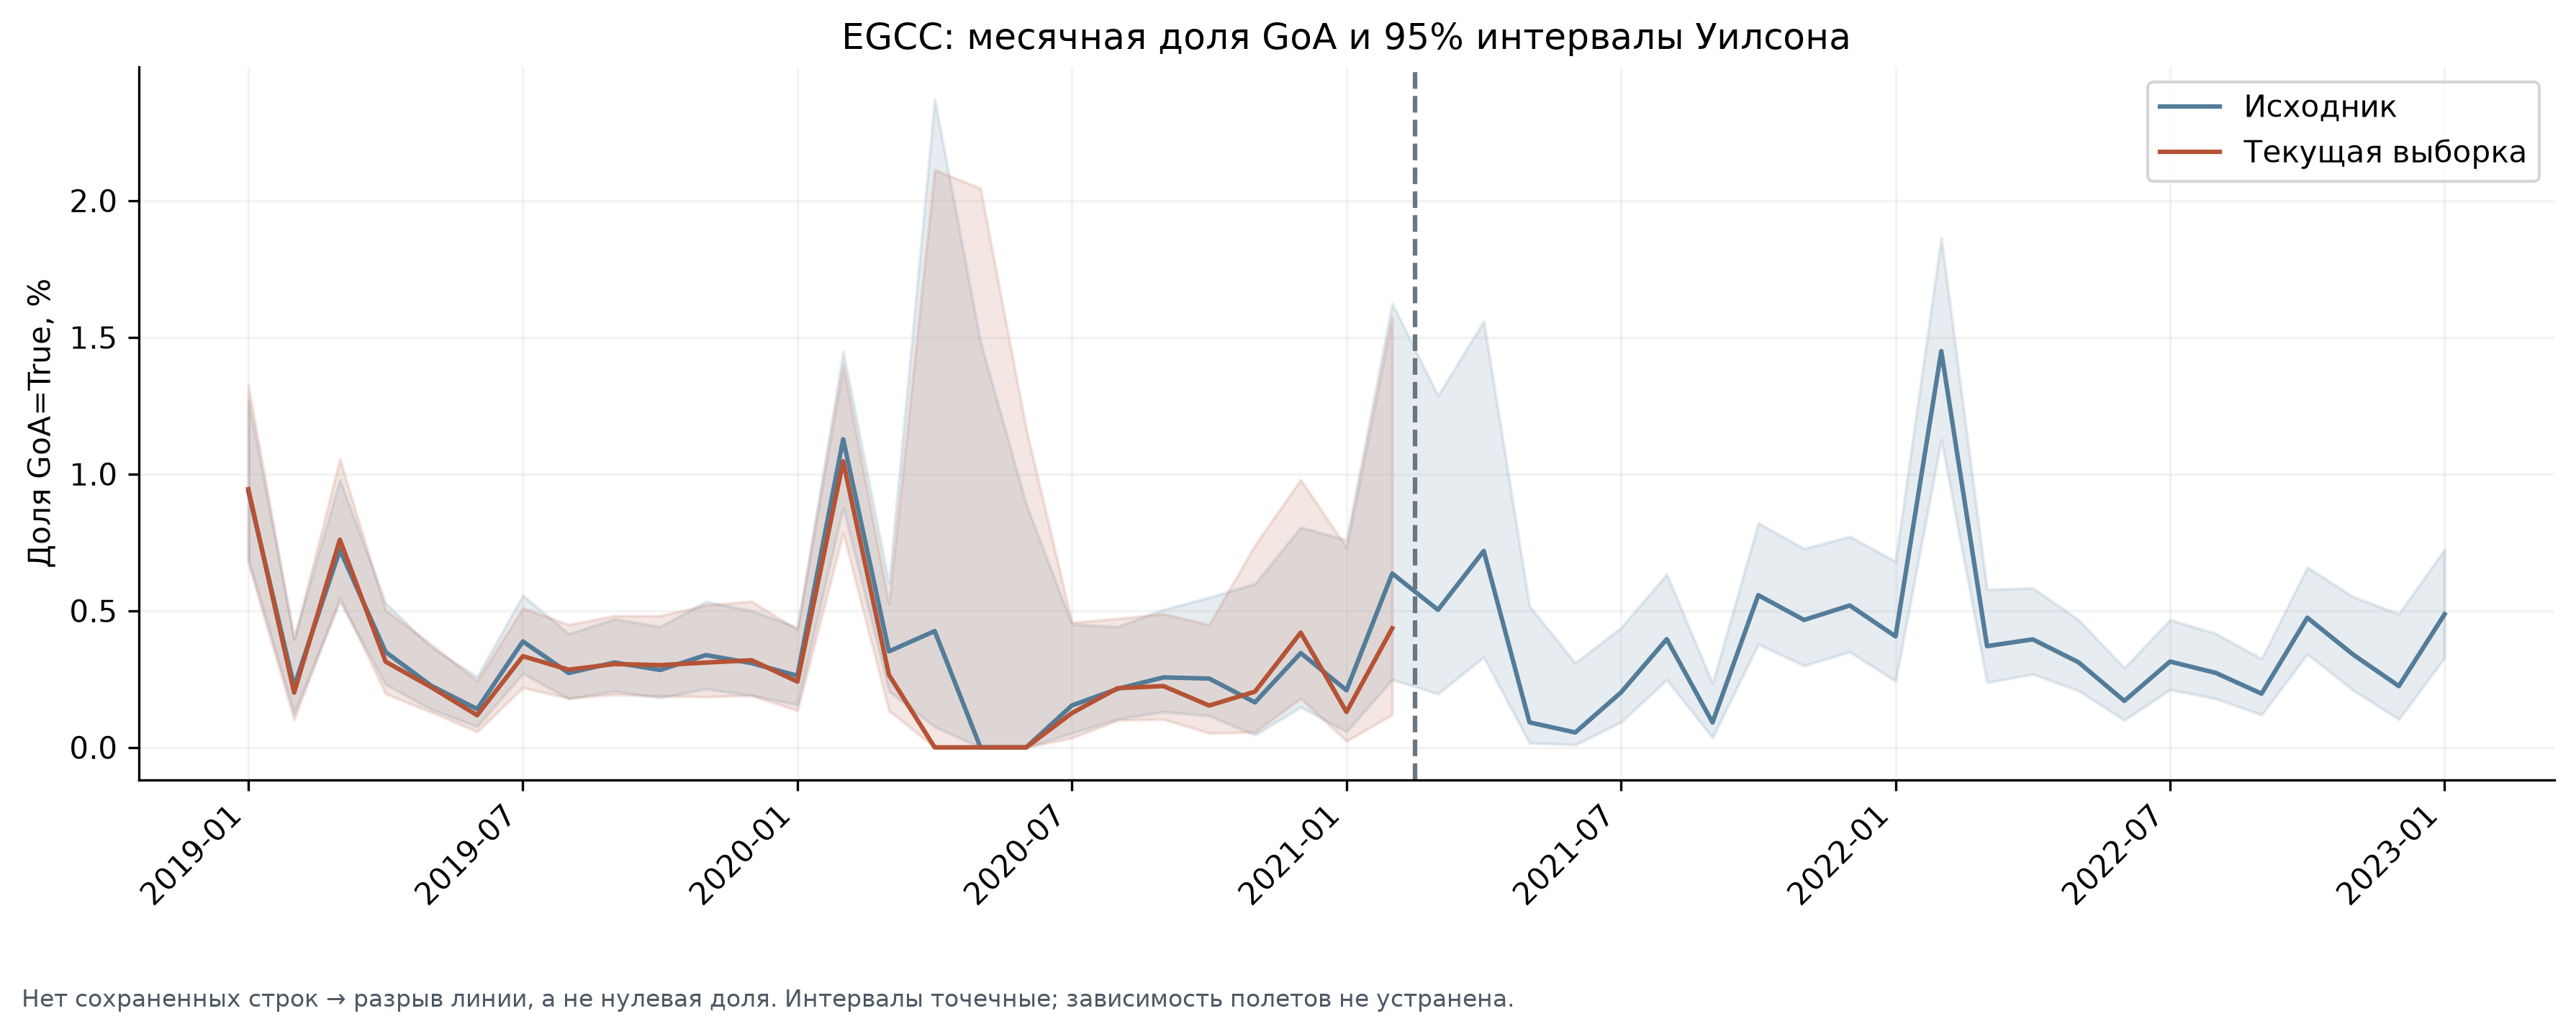

In [3]:
display(Image(filename=str(FIGURES/'07_03_egcc_rates.png')))

## Полное разделение причин

Каждая исходная строка относится ровно к одной группе: сохранена, нет C40, C40 не раньше первой отметки или прежнее исключение пары.

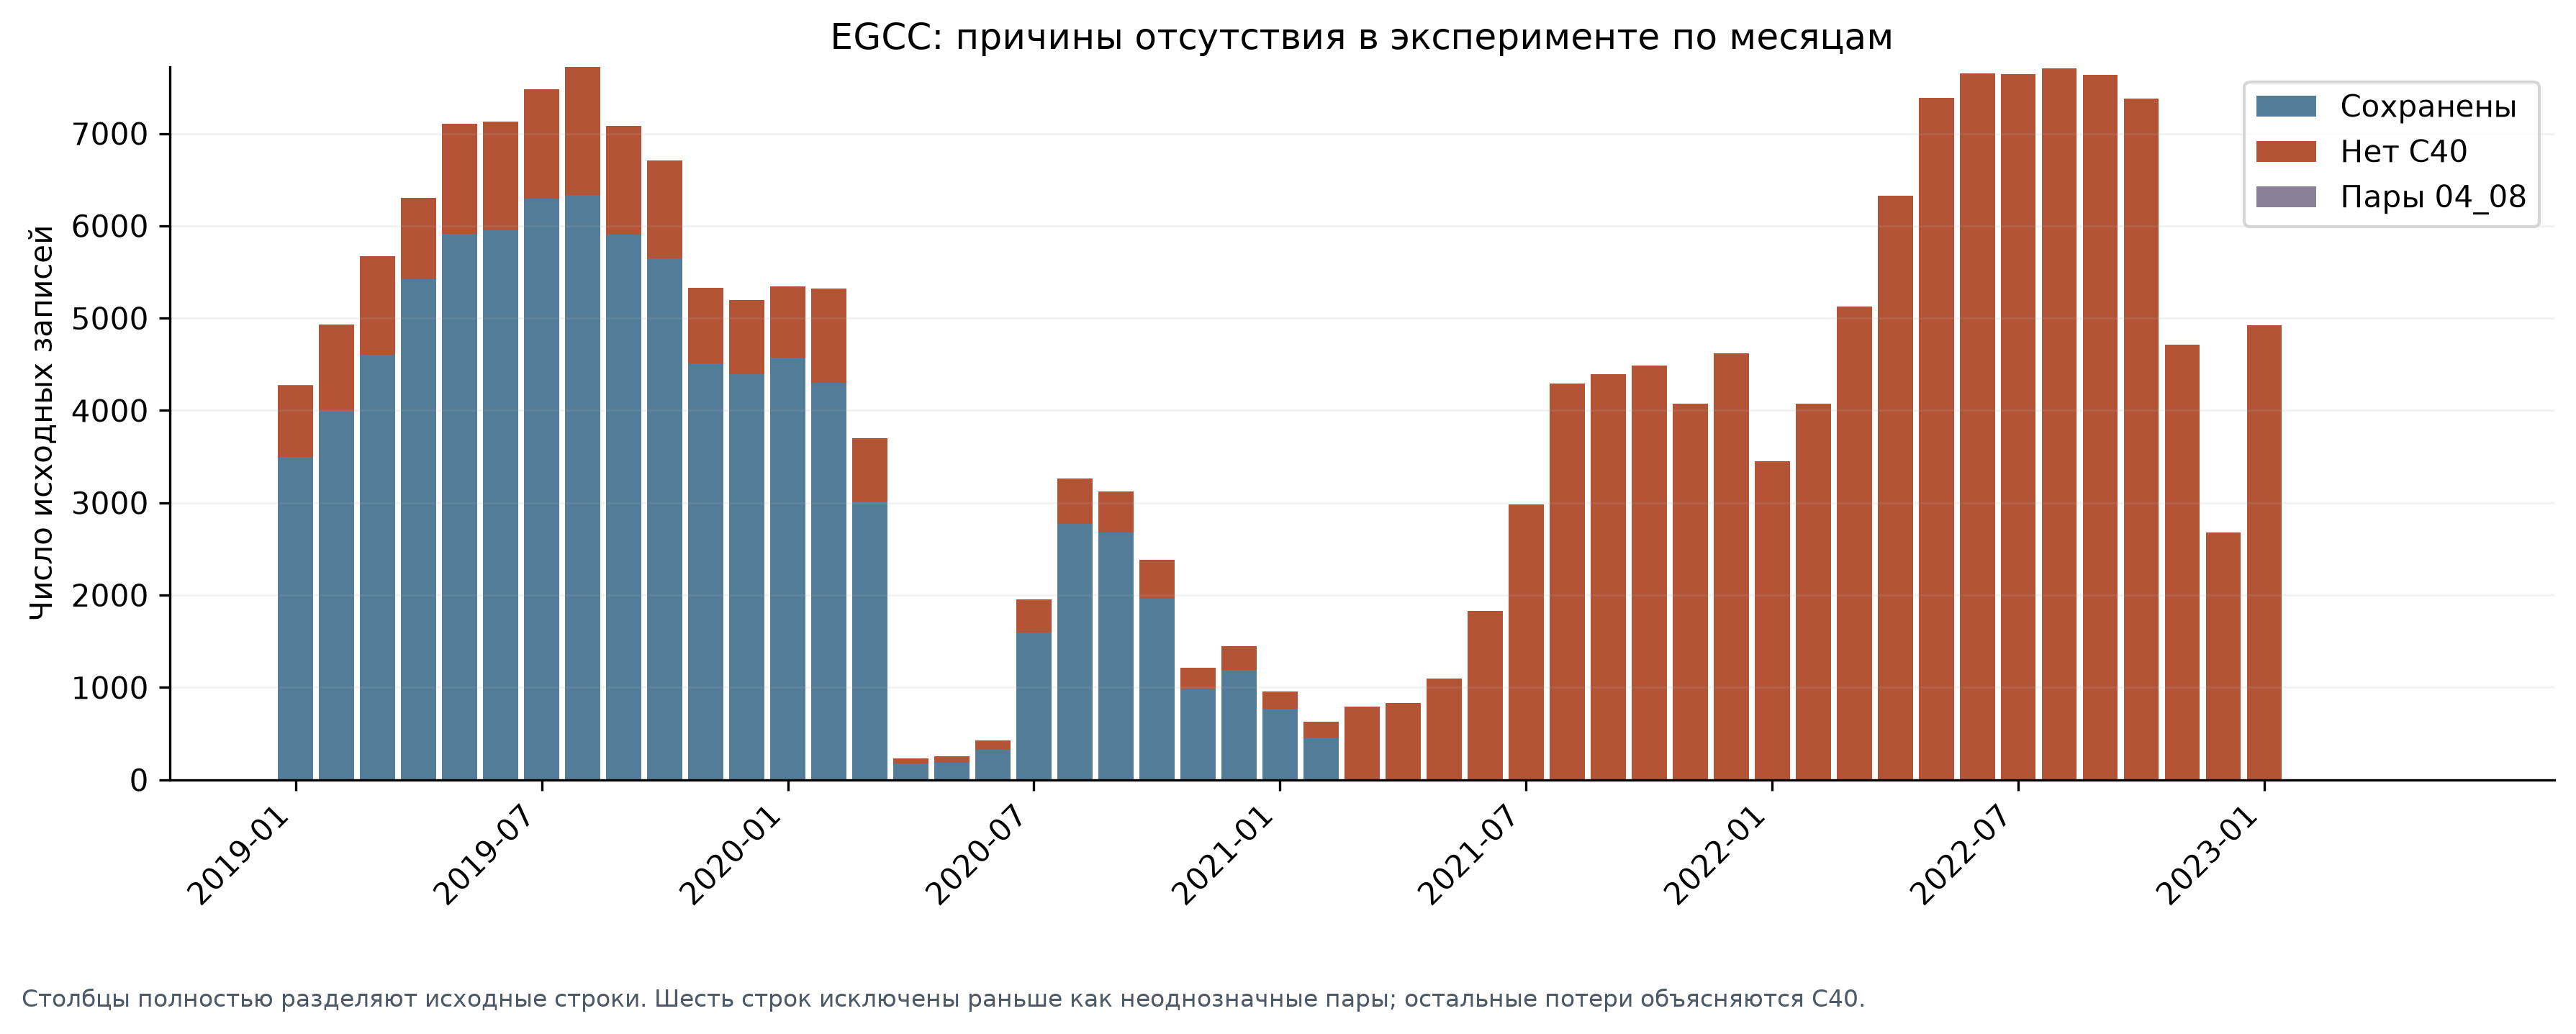

In [4]:
display(Image(filename=str(FIGURES/'07_04_egcc_reasons.png')))

## Исходный и текущий состав

Поздний исходный период показан отдельно. Внутри каждой метки категории типов и сегментов могут различаться; сравнение состава не является оценкой причин риска.

In [5]:
composition=pd.read_csv(REPORT/'07_02_composition.csv')
display(composition.sort_values(['population','GoA','field','rows'],ascending=[True,True,True,False]).groupby(['population','GoA','field']).head(5))
display(pd.read_csv(REPORT/'07_02_prior_pair_exclusions.csv'))

,GoA,value,rows,field,population,within_label_percent
615,False,Lowcost,49719,market_segment,current,57.063664
616,False,Mainline,25291,market_segment,current,29.027075
612,False,(пропуск),5507,market_segment,current,6.320513
620,False,Regional,4024,market_segment,current,4.618439
613,False,Business,1705,market_segment,current,1.956869
471,False,B738,30104,typecode,current,34.551068
449,False,A320,13515,typecode,current,15.511483
447,False,A319,8366,typecode,current,9.601855
443,False,A20N,5398,typecode,current,6.195411
450,False,A321,3850,typecode,current,4.418735


,flight_id,icao24,airport,landing_time,GoA,n_attempts,C40_CROSS_TIME,typecode,market_segment,c40_status,retained
0,RYR46ZU_60726,4ca701,EGCC,2019-01-10 18:38:38+00:00,False,1,2019-01-10 18:15:30+00:00,B738,Lowcost,strictly_before_first,False
1,EZY78QA_20033,40643b,EGCC,2019-01-10 18:54:25+00:00,False,1,2019-01-10 18:30:13+00:00,A320,Lowcost,strictly_before_first,False
2,RYR46ZU_60727,4ca701,EGCC,2019-01-10 18:57:24+00:00,False,1,2019-01-10 18:15:30+00:00,B738,Lowcost,strictly_before_first,False
3,EZY78QA_20034,40643b,EGCC,2019-01-10 19:09:23+00:00,False,1,2019-01-10 18:30:13+00:00,A320,Lowcost,strictly_before_first,False
4,TOM367_19029,4062a3,EGCC,2019-01-17 22:32:33+00:00,False,1,2019-01-17 22:14:34+00:00,B752,Lowcost,strictly_before_first,False
5,TOM367_19030,4062a3,EGCC,2019-01-17 22:52:51+00:00,False,1,2019-01-17 22:14:34+00:00,B752,Lowcost,strictly_before_first,False


## Выводы и следующий вопрос

C40 не восстанавливаем из будущих событий; временной провал не доказывает прекращение рейсов. Статус EGCC в выборке не меняется без отдельного решения.

In [6]:
display(Markdown((REPORT/'07_02_review.md').read_text(encoding='utf8')))

# 07_02 – EGCC: временное покрытие и C40

Проверены все 211,299 исходных записей EGCC (791 GoA=True) и все 87,435 сохраненных (306 GoA=True). Источники проверены по SHA256 до и после; новых исключений и исправлений нет.

## Что установлено

С 01.03.2021 в исходнике есть **106,096 записей**, включая **401 GoA=True**, но у всех отсутствует C40_CROSS_TIME. Ни одна не попала в текущий C40-эксперимент. Последняя сохраненная посадка: 2021-02-28T21:20:45+00:00.

Длинный разрыв до общей границы 30.05.2023 составляет 821 дней: в 679 есть исходные записи, но нет сохраненных из-за C40; в 142 дней записей нет уже в исходнике. Последняя исходная запись EGCC: 2023-01-30T23:38:19+00:00. Отсутствие записей само по себе не доказывает прекращение рейсов или уходов.

До границы марта 2021 исходник содержит 105,203 строк, 390 GoA=True. Шесть строк с допустимым C40 не сохранены из-за прежнего исключения неоднозначных пар 04_08; все GoA=False. Совпадение этих строк с архивом пар проверено по составному ключу icao24 + airport + landing_time.

## Причины и сравнение классов

| Период | Причина | n | GoA=True | Доля, % |
| --- | --- | ---: | ---: | ---: |
| before_2021_03 | ambiguous_pair_04_08 | 6 | 0 | 0.000 |
| before_2021_03 | missing | 17,762 | 84 | 0.473 |
| before_2021_03 | retained | 87,435 | 306 | 0.350 |
| from_2021_03 | missing | 106,096 | 401 | 0.378 |

Общий охват 41,4% складывается прежде всего из потери целого позднего периода. Нельзя интерпретировать отличие общих долей GoA исходника и текущей выборки как чистое влияние фильтра: сравниваются разные календарные составы. Таблица composition.csv разделяет исходный ранний период, поздний период и текущую выборку, отдельно по обоим классам.

## Границы вывода и следующий вопрос

Механизм отсутствия C40 не установлен: возможен разрыв обогащения или сопоставления источников, но это гипотеза. Не объявлять поздние полеты ошибочными и не восстанавливать C40 по посадке. Исходные поздние записи уже сохранены вне эксперимента этапа 04. Ни неисправность борта, ни прекращение полетов из этих данных не следуют.

EGCC пока сохраняется. Следующее решение – как использовать его неполный период в сравнении аэропортов и временном разбиении модели. Удаление всего аэропорта не требуется автоматически. Февраль 2020 с 45 отмеченными уходами в 4 301 сохраненной записи остается отдельным вопросом; погодная причина этим разбором не проверена.

## Артефакты

`07_02_period_reasons.csv`, `07_02_monthly_reasons.csv`, `07_02_monthly_comparison.csv`, `07_02_prior_pair_exclusions.csv`, `07_02_composition.csv`, `07_02_calendar_difference.csv`, `07_02_audit.json`. Графики – `europe/figures/07_airports/EGCC/`, PNG 300 dpi, SVG и PDF. Пропуски типов и сегментов в таблице состава показаны как категория, исходные значения не переписаны.




## Принятое решение – 09.10.2026

EGCC оставлен за доступный период C40: 87 435 строк, 306 GoA=True, до конца февраля 2021. При моделировании обязательна проверка чувствительности с EGCC и без него на одинаковом тесте остальных аэропортов. Частоты дополнительно сравниваются за общий календарный период. Поздние записи без C40 используются только описательно, вне модели C40. Решение по составу закрыто; проверки моделей запланированы, еще не выполнены.

[План чувствительности](../../../reports/airports/EGCC/07_02_decision_and_sensitivity.md).